In [1]:
import pathlib
import sys
module_dir = pathlib.Path("").parent.resolve()
root_dir = module_dir.parent
asvlite_wrapper_dir = root_dir.joinpath("dependency", "ASVLite", "wrapper", "cython")
sys.path.insert(0, str(asvlite_wrapper_dir))

In [2]:
import numpy as np

In [3]:
import math
from sea_surface import py_Sea_surface
from asv import py_Asv_specification, py_Asv
from geometry import py_Coordinates_3D
import matplotlib.pyplot as plt

plt.rcParams['figure.figsize'] = [18, 5]

In [4]:
# Simulation time step size
time_step_size = 40 # milli-sec

In [5]:
def simulate(time_duration, sea_surface, asv):
    '''
    Function to simulate the dynamics of an ASV on a given sea_surface for a given time_duration (sec).
    '''
    positions = [] # store asv positions
    attitudes = [] # store asv attitudes
    accelerations = [] # store asv accelerations
    elevations= [] # store sea surface elivations
    # Simulation is performed for the duration defined above with a time step size of 40 milli sec.
    for i in range(int(time_duration * 1000.0 /time_step_size)):  
        time = i * time_step_size/1000.0
        # Record the position, attitude and elevation for ploting
        position = asv.py_get_position_cog() # Get current position of the ASV
        positions.append(position)
        attitude = asv.py_get_attitude() # Get current attitude of the ASV
        attitudes.append(attitude)
        acceleration = asv.py_get_A()
        accelerations.append(acceleration)
        elevation= sea_surface.py_get_elevation(position, time)
        elevations.append(elevation)
        # Compute asv dynamics
        asv.py_compute_dynamics(time_step_size)
    return(positions, attitudes, accelerations, elevations)

In [6]:
# ASV spec
asv_spec = py_Asv_specification()
asv_spec.L_wl       = 2.1 # m
asv_spec.B_wl       = 0.6 # m
asv_spec.D          = 0.25 # m 
asv_spec.T          = 0.09 # m
asv_spec.max_speed  = 4.0 # m/s
asv_spec.disp       = 0.09 # m3
asv_spec.r_roll     = 0.2 # m
asv_spec.r_pitch    = 0.6 # m
asv_spec.r_yaw      = 0.6 # m
asv_spec.cog        = py_Coordinates_3D(1.05, 0.0, -0.2) # m

In [8]:
# Simulation time in seconds
time_duration = 60 # sec

## Experiment 1 - Sync using sea surface elevations

- asv_1 and asv_2 placed at two different locations.
- Both asvs will collect the sea surface elevations at its location.
- The asvs will then compute the perdominant wave frequency using FFT and will move to a new position to synchronise there heave motions. 
- The new position will be computed from the intial position moving along the direction of propagation of the predominant swell.

In [27]:
# Sea surface
wave_rand_seed = 1
count_wave_spectral_directions = 5
count_wave_spectral_frequencies = 7
wave_hs = 1.2 # Significant wave height in m
wave_dp = math.pi/4 # wave direction of propagation 45 deg N
sea_surface = py_Sea_surface(wave_hs, wave_dp, wave_rand_seed, count_wave_spectral_directions, count_wave_spectral_frequencies)

In [9]:
# Start position and attitude
start_attitude = py_Coordinates_3D(0.0, 0.0, 0.0) # Both ASVs will have the same initial attitude
position_1 = py_Coordinates_3D(100.0, 100.0)
position_2 = py_Coordinates_3D(2500.0, 2500.0)

In [10]:
# Initialise ASV
asv_1 = py_Asv(asv_spec, sea_surface, position_1, start_attitude)
asv_2 = py_Asv(asv_spec, sea_surface, position_2, start_attitude)

In [11]:
# Simulate
positions_1, attitudes_1, accelerations_1, elevations_1 = simulate(time_duration, sea_surface, asv_1)
positions_2, attitudes_2, accelerations_2, elevations_2 = simulate(time_duration, sea_surface, asv_2)

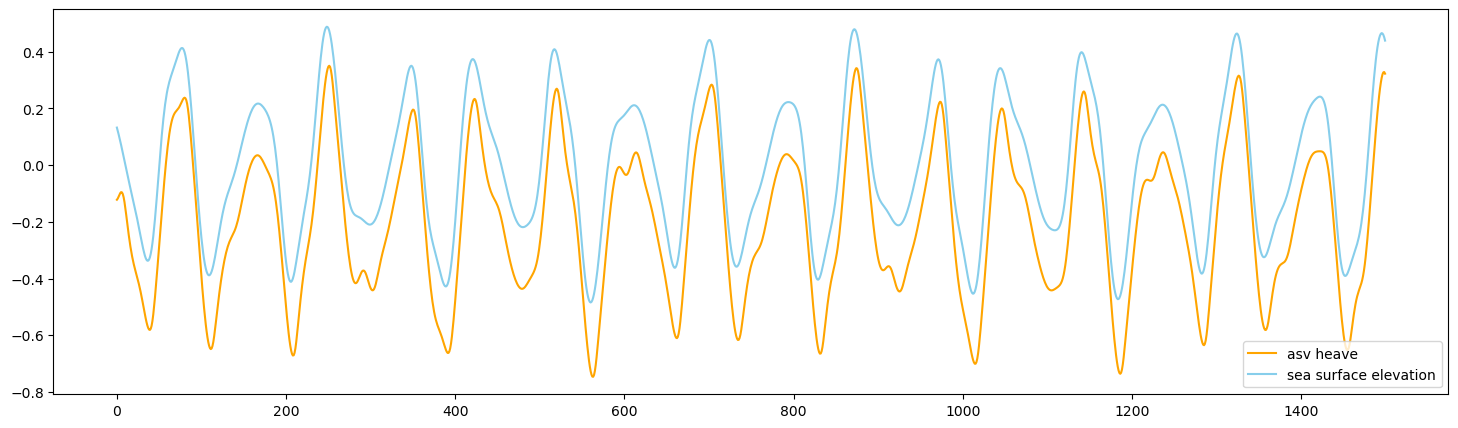

In [12]:
# Plot ASV heave and sea surface elevations
heave_positions = [position.z  for position  in positions_1]
plt.plot(heave_positions, label="asv heave", color="orange")
plt.plot(elevations_1, label="sea surface elevation", color="skyblue")
plt.legend()

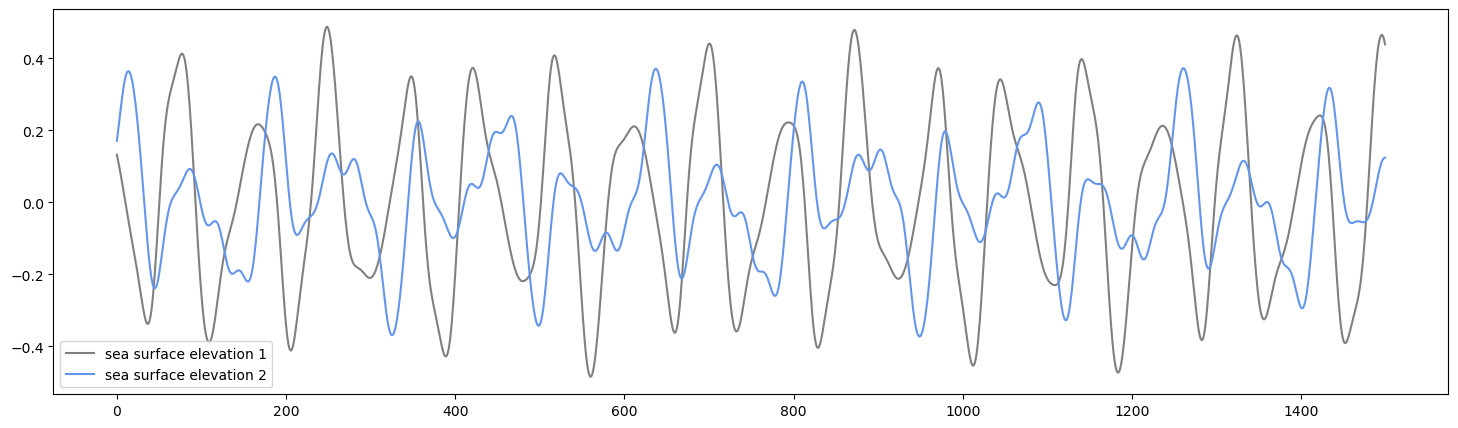

In [13]:
# Plot the sea surface elevations recorded by the two ASVs
plt.plot(elevations_1, label="sea surface elevation 1", color="grey")
plt.plot(elevations_2, label="sea surface elevation 2", color="cornflowerblue")
plt.legend()

In [14]:
# # Make a normalised plot
# trimmer_size = 100
# # trimmer_size = int((5 * 60)/(time_step_size/1000))
# np_elevations = np.array(elevations[trimmer_size:])
# np_heave_positions = np.array([position.z  for position  in positions[trimmer_size:]])
# def normalise_vector(vector):
#     vector = vector - np.mean(vector)
#     vector = vector/np.max(np.abs(vector))
#     return vector

# normalised_elevations = normalise_vector(np_elevations)
# normalised_heave_positions = normalise_vector(np_heave_positions)


# # plot
# plt.plot(normalised_elevations, label="sea surface elevation", color="skyblue")
# plt.plot(normalised_heave_positions, label="heave positions", color="orange")
# plt.legend()


### Fast Fourier Transform

In [15]:
def fast_fourier_transform(vector):
    n = len(vector)
    fhat = np.fft.fft(vector)
    PSD = fhat * np.conj(fhat) # Power Spectral Density (Power Spectrum)
    freq = np.fft.fftfreq(len(vector), d=time_step_size/1000)
    i_max = np.argmax(PSD) # index corresponding to max power
    L = np.arange(1, np.floor(n/2), dtype="int")
    return(L, fhat, freq, PSD, i_max)

In [16]:
L_1, fhat_1, freq_1, PSD_1, i_max_1 = fast_fourier_transform(elevations_1)
L_2, fhat_2, freq_2, PSD_2, i_max_2 = fast_fourier_transform(elevations_2)

/home/toby/micromamba/envs/seasyncsquad/lib/python3.11/site-packages/matplotlib/cbook/__init__.py:1340: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


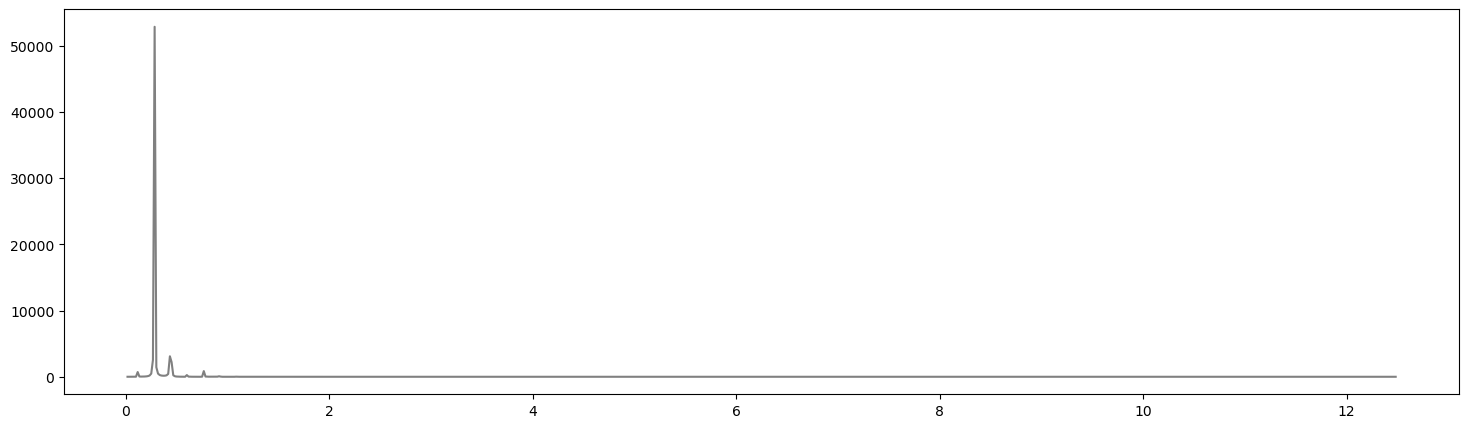

In [17]:
plt.plot(freq_1[L_1], PSD_1[L_1], color="grey")

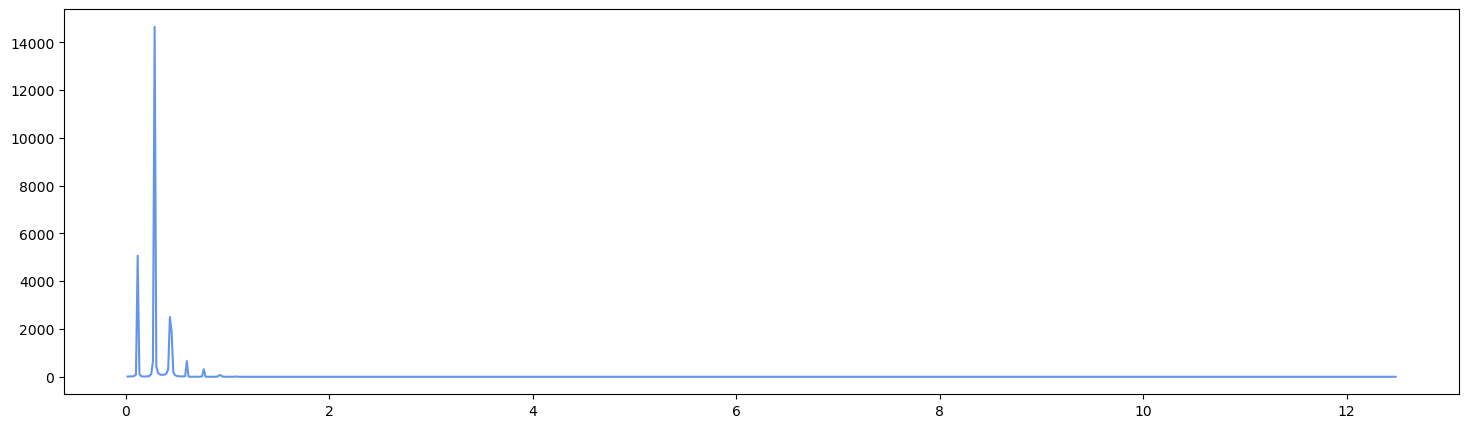

In [18]:
plt.plot(freq_2[L_2], PSD_2[L_2], color="cornflowerblue")

In [19]:
f_max_1 = abs(freq_1[i_max_1])
f_max_2 = abs(freq_2[i_max_2])
print("Peak freq for ASV_1 = ", f_max_1)
print("Peak freq for ASV_2 = ", f_max_2)

Peak freq for ASV_1 =  0.2833333333333333
Peak freq for ASV_2 =  0.2833333333333333


In [20]:
sea_surface.py_get_peak_spectral_frequency()

0.18263810872998018

In [21]:
wave_length_1 = 9.81/(2.0* np.pi * f_max_1 * f_max_1)
wave_length_2 = 9.81/(2.0* np.pi * f_max_2 * f_max_2)
print("Wave length as observed by ASV_1 = ", wave_length_1)
print("Wave length as observed by ASV_1 = ", wave_length_2)

Wave length as observed by ASV_1 =  19.448844187658743
Wave length as observed by ASV_1 =  19.448844187658743


### Find the nearest positions to move to

In [22]:
reference_point = (0, 0)
distance_1 = (position_1.x**2 + position_1.y**2)**0.5
distance_2 = (position_2.x**2 + position_2.y**2)**0.5
print(distance_1, distance_2)

141.4213562373095 3535.5339059327375


In [23]:
a_1 = int(distance_1/wave_length_1) * wave_length_1/(2**0.5)
new_position_1 = py_Coordinates_3D(a_1, a_1)
print(a_1)

a_2 = int(distance_2/wave_length_2) * wave_length_2/(2**0.5)
new_position_2 = py_Coordinates_3D(a_2, a_2)
print(a_2)

96.26686727933846
2489.186139651466


### Simulate with new positions

In [24]:
# Initialise ASV
asv_1 = py_Asv(asv_spec, sea_surface, new_position_1, start_attitude)
asv_2 = py_Asv(asv_spec, sea_surface, new_position_2, start_attitude)

In [25]:
# Simulate
positions_1, attitudes_1, accelerations_1, elevations_1 = simulate(time_duration, sea_surface, asv_1)
positions_2, attitudes_2, accelerations_2, elevations_2 = simulate(time_duration, sea_surface, asv_2)

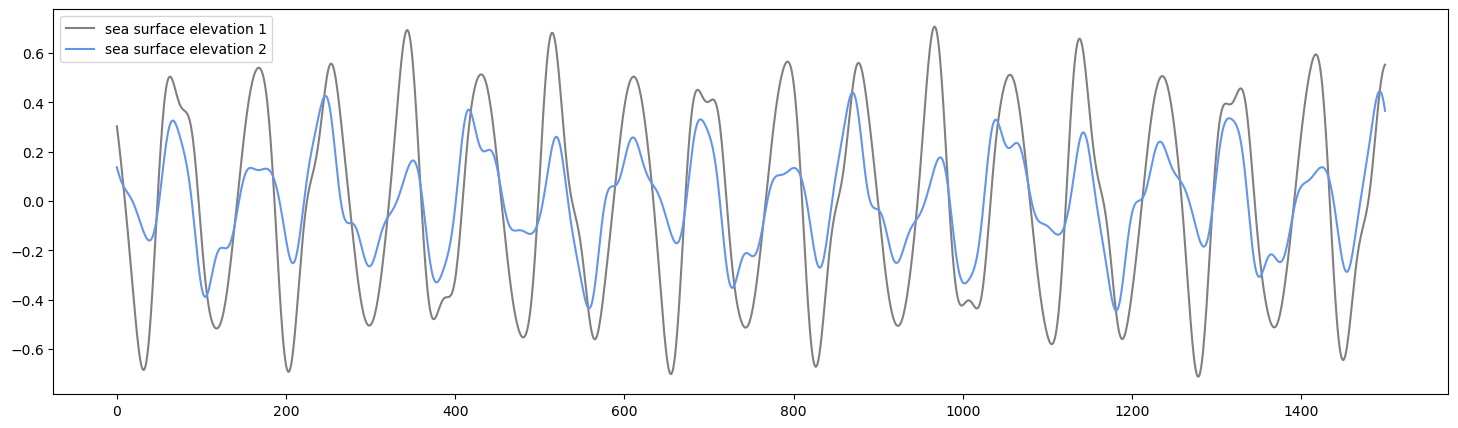

In [26]:
# Plot the sea surface elevations recorded by the two ASVs
plt.plot(elevations_1, label="sea surface elevation 1", color="grey")
plt.plot(elevations_2, label="sea surface elevation 2", color="cornflowerblue")
plt.legend()

1. Exp 1 should be to position the vehicle at the along multiple of peak wave frequency along the direction of the predominant wave.
2. Wave heading is set at 45.
3. ASVs are all placed along the 45 deg line from origin
4. The reference point is 0,0
5. When moved to the new position it is moved to such that both x and y coordinates are the same. This should be changed to
       1. move to the nearest point by drawing a circle.
       2. moved to the nearest point along the direction of the predominant wave.
6. Finally when simulating again after moving to the new position, the simulation should not restart, instead should continue from the time the first simulation was stoped. 